<a href="https://colab.research.google.com/github/Nhut214/vietnamese_student_feedback_sentiment_analysis/blob/main/notebooks/05_PhoBERT_UIT_VSFC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Gỡ các phiên bản cũ có thể gây xung đột
!pip uninstall -y \
    transformers \
    huggingface_hub \
    tokenizers \
    gradio \
    gradio_client \
    > /dev/null 2>&1

# Cài bộ phiên bản thống nhất
!pip install -q \
    "transformers==4.45.2" \
    "huggingface_hub==0.36.2" \
    "accelerate==1.0.1" \
    "sentencepiece==0.2.0" \
    "safetensors>=0.4.5" \
    "underthesea"

print("Đã cài đặt thư viện thành công.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.4/44.4 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 79.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 22.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 330.9/330.9 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 54.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 69.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 51.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 39.8 MB/s eta 0:00:00
Đã cài đặt thư viện thành công.


In [ ]:
from huggingface_hub import login

login()

In [ ]:
from huggingface_hub import whoami

print("Tài khoản:", whoami()["name"])
print("Có model:", "model" in globals())
print("Có tokenizer:", "tokenizer" in globals())

Tài khoản: hnhut
Có model: False
Có tokenizer: False


In [ ]:
import torch
import transformers
import huggingface_hub

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print(
    "Hugging Face Hub:",
    huggingface_hub.__version__
)
print(
    "Có GPU:",
    torch.cuda.is_available()
)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

PyTorch: 2.11.0+cu128
Transformers: 4.45.2
Hugging Face Hub: 0.36.2
Có GPU: True
GPU: Tesla T4


In [ ]:
from transformers import AutoTokenizer

MODEL_NAME = "vinai/phobert-base-v2"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=False
)

print(
    "Đã tải tokenizer:",
    type(tokenizer).__name__
)

sample = "Giảng_viên giảng_bài rất dễ_hiểu."

encoded = tokenizer(
    sample,
    return_tensors="pt"
)

print("Kiểm tra mã hóa:")
print(encoded)

config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

bpe.codes: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Đã tải tokenizer: PhobertTokenizer
Kiểm tra mã hóa:
{'input_ids': tensor([[    0, 18954, 60382,   387,    59, 56306,  6873, 22324, 28463,     2]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}


Mounted at /content/drive
Đường dẫn dữ liệu: /content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/Data
Train: (11426, 3)
Validation: (1583, 3)
Test: (3166, 3)

Phân bố nhãn tập train:
sentiment
Negative    5325
Neutral      458
Positive    5643
Name: count, dtype: int64


,sentence,sentiment,topic
0,slide giáo trình đầy đủ .,2,1
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",2,0
2,đi học đầy đủ full điểm chuyên cần .,0,1
3,chưa áp dụng công nghệ thông tin và các thiết ...,0,0
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...",2,0


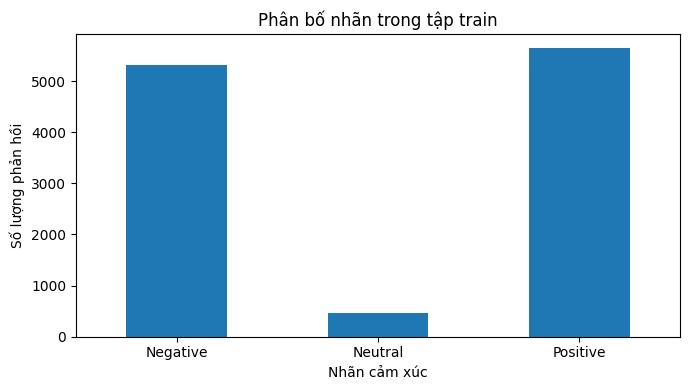

In [ ]:

from google.colab import drive
drive.mount("/content/drive")

import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

LABEL_IDS = [0, 1, 2]
LABEL_NAMES = ["Negative", "Neutral", "Positive"]
ID2LABEL = {0: "Negative", 1: "Neutral", 2: "Positive"}
LABEL2ID = {"Negative": 0, "Neutral": 1, "Positive": 2}

DATA_DIR = r"/content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/Data"

TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
VALIDATION_PATH = os.path.join(DATA_DIR, "validation.csv")
TEST_PATH = os.path.join(DATA_DIR, "test.csv")

for path in [TRAIN_PATH, VALIDATION_PATH, TEST_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Không tìm thấy file: {path}\n"
            "Hãy kiểm tra lại tên thư mục và tên file trong Google Drive."
        )

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VALIDATION_PATH)
test_df = pd.read_csv(TEST_PATH)

def clean_dataframe(df, name):
    required_columns = {"sentence", "sentiment"}
    missing_columns = required_columns - set(df.columns)

    if missing_columns:
        raise ValueError(
            f"Tập {name} thiếu các cột bắt buộc: {missing_columns}"
        )

    cleaned = df.dropna(subset=["sentence", "sentiment"]).copy()
    cleaned["sentence"] = cleaned["sentence"].astype(str).str.strip()
    cleaned["sentiment"] = pd.to_numeric(
        cleaned["sentiment"],
        errors="coerce"
    )
    cleaned = cleaned.dropna(subset=["sentiment"])
    cleaned["sentiment"] = cleaned["sentiment"].astype(int)
    cleaned = cleaned[
        cleaned["sentiment"].isin(LABEL_IDS)
    ]
    cleaned = cleaned[
        cleaned["sentence"].str.len() > 0
    ].reset_index(drop=True)

    return cleaned

train_df = clean_dataframe(train_df, "train")
val_df = clean_dataframe(val_df, "validation")
test_df = clean_dataframe(test_df, "test")

# Các biến nhãn được tạo ngay sau khi đọc dữ liệu.
y_train = train_df["sentiment"].to_numpy(dtype=np.int64)
y_val = val_df["sentiment"].to_numpy(dtype=np.int64)
y_test = test_df["sentiment"].to_numpy(dtype=np.int64)

print("Đường dẫn dữ liệu:", DATA_DIR)
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nPhân bố nhãn tập train:")
print(
    train_df["sentiment"]
    .value_counts()
    .reindex(LABEL_IDS, fill_value=0)
    .rename(index=ID2LABEL)
)

display(train_df.head())

train_counts = (
    train_df["sentiment"]
    .value_counts()
    .reindex(LABEL_IDS, fill_value=0)
    .rename(index=ID2LABEL)
)

train_counts.plot(kind="bar", figsize=(7, 4))
plt.title("Phân bố nhãn trong tập train")
plt.xlabel("Nhãn cảm xúc")
plt.ylabel("Số lượng phản hồi")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

RESULTS = []

def evaluate_predictions(
    model_name,
    experiment,
    y_true,
    y_pred,
    show_confusion_matrix=True
):
    accuracy = accuracy_score(y_true, y_pred)

    macro_precision, macro_recall, macro_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=LABEL_IDS,
            average="macro",
            zero_division=0
        )
    )

    _, _, weighted_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=LABEL_IDS,
        average="weighted",
        zero_division=0
    )

    class_precision, class_recall, class_f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=LABEL_IDS,
            average=None,
            zero_division=0
        )
    )

    result = {
        "Model": model_name,
        "Experiment": experiment,
        "Accuracy": accuracy,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Negative Precision": class_precision[0],
        "Negative Recall": class_recall[0],
        "Negative F1": class_f1[0],
        "Neutral Precision": class_precision[1],
        "Neutral Recall": class_recall[1],
        "Neutral F1": class_f1[1],
        "Positive Precision": class_precision[2],
        "Positive Recall": class_recall[2],
        "Positive F1": class_f1[2],
        "Neutral Support": int(support[1]),
    }

    RESULTS.append(result)

    print(f"\n{model_name} — {experiment}")
    print("=" * 72)
    print(
        classification_report(
            y_true,
            y_pred,
            labels=LABEL_IDS,
            target_names=LABEL_NAMES,
            digits=4,
            zero_division=0
        )
    )

    if show_confusion_matrix:
        matrix = confusion_matrix(
            y_true,
            y_pred,
            labels=LABEL_IDS
        )
        display_matrix = ConfusionMatrixDisplay(
            matrix,
            display_labels=LABEL_NAMES
        )
        display_matrix.plot(values_format="d")
        plt.title(f"{model_name} — {experiment}")
        plt.tight_layout()
        plt.show()

    return result


def export_results(filename):
    if not RESULTS:
        raise ValueError("Chưa có kết quả để xuất.")

    result_df = (
        pd.DataFrame(RESULTS)
        .drop_duplicates(
            subset=["Model", "Experiment"],
            keep="last"
        )
        .reset_index(drop=True)
    )

    metric_columns = [
        column
        for column in result_df.columns
        if column not in [
            "Model",
            "Experiment",
            "Neutral Support"
        ]
    ]

    display_df = result_df.copy()
    display_df[metric_columns] = (
        display_df[metric_columns].round(4)
    )

    display(display_df)

    output_path = os.path.join(
        "/content/drive/MyDrive/NC_MatCanBang_UIT_VSFC",
        filename
    )
    result_df.to_csv(output_path, index=False)

    print("Đã lưu kết quả tại:", output_path)
    return result_df



## 1. Cấu hình PhoBERT

- Mô hình: `vinai/phobert-base-v2`
- Tách từ: `underthesea`
- Baseline: Cross Entropy thông thường
- Xử lý mất cân bằng: Weighted Cross Entropy


In [ ]:

import gc
import torch

from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

from sklearn.utils.class_weight import (
    compute_class_weight
)

from tqdm.auto import tqdm
from underthesea import word_tokenize

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Thiết bị:", DEVICE)

MODEL_NAME = "vinai/phobert-base-v2"
MAX_LENGTH = 128
BATCH_SIZE = 16
EPOCHS = 2
LEARNING_RATE = 2e-5

class_values = np.array(LABEL_IDS)

class_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=class_values,
    y=y_train
)

CLASS_WEIGHT = {
    int(label): float(weight)
    for label, weight in zip(
        class_values,
        class_weight_values
    )
}

print("Trọng số lớp:", CLASS_WEIGHT)


Thiết bị: cuda
Trọng số lớp: {0: 0.7152425665101722, 1: 8.315866084425036, 2: 0.674936499497903}



## 2. Tách từ và mã hóa dữ liệu


In [ ]:

def segment_vietnamese_texts(series, description):
    texts = series.astype(str).tolist()

    segmented_texts = [
        word_tokenize(text, format="text")
        for text in tqdm(
            texts,
            desc=description
        )
    ]

    return segmented_texts

train_texts = segment_vietnamese_texts(
    train_df["sentence"],
    "Tách từ train"
)

val_texts = segment_vietnamese_texts(
    val_df["sentence"],
    "Tách từ validation"
)

test_texts = segment_vietnamese_texts(
    test_df["sentence"],
    "Tách từ test"
)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=False
)

print(train_texts[:3])


Tách từ train:   0%|          | 0/11426 [00:00<?, ?it/s]

Tách từ validation:   0%|          | 0/1583 [00:00<?, ?it/s]

Tách từ test:   0%|          | 0/3166 [00:00<?, ?it/s]

['slide giáo_trình đầy_đủ .', 'nhiệt_tình giảng_dạy , gần_gũi với sinh_viên .', 'đi học đầy_đủ full_điểm chuyên cần .']


In [ ]:

class SentimentDataset(Dataset):
    def __init__(
        self,
        texts,
        labels,
        tokenizer,
        max_length
    ):
        self.encodings = tokenizer(
            texts,
            truncation=True,
            padding=True,
            max_length=max_length
        )

        self.labels = [
            int(label)
            for label in labels
        ]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        item = {
            key: torch.tensor(
                value[index],
                dtype=torch.long
            )
            for key, value
            in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            self.labels[index],
            dtype=torch.long
        )

        return item


train_dataset = SentimentDataset(
    train_texts,
    y_train,
    tokenizer,
    MAX_LENGTH
)

validation_dataset = SentimentDataset(
    val_texts,
    y_val,
    tokenizer,
    MAX_LENGTH
)

test_dataset = SentimentDataset(
    test_texts,
    y_test,
    tokenizer,
    MAX_LENGTH
)


def create_data_loaders():
    generator = torch.Generator()
    generator.manual_seed(SEED)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

    return (
        train_loader,
        validation_loader,
        test_loader
    )



## 3. Hàm huấn luyện và đánh giá PhoBERT


In [ ]:

@torch.no_grad()
def predict_with_phobert(model, data_loader):
    model.eval()

    all_labels = []
    all_predictions = []

    for batch in tqdm(
        data_loader,
        desc="Đánh giá",
        leave=False
    ):
        labels = batch["labels"].to(DEVICE)

        inputs = {
            key: value.to(DEVICE)
            for key, value in batch.items()
            if key != "labels"
        }

        outputs = model(**inputs)
        predictions = outputs.logits.argmax(dim=1)

        all_labels.extend(
            labels.cpu().numpy()
        )
        all_predictions.extend(
            predictions.cpu().numpy()
        )

    return (
        np.array(all_labels),
        np.array(all_predictions)
    )


def calculate_macro_f1(y_true, y_pred):
    _, _, macro_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=LABEL_IDS,
            average="macro",
            zero_division=0
        )
    )

    return macro_f1


def train_phobert(
    experiment,
    use_class_weight=False
):
    (
        train_loader,
        validation_loader,
        test_loader
    ) = create_data_loaders()

    model = (
        AutoModelForSequenceClassification
        .from_pretrained(
            MODEL_NAME,
            num_labels=3,
            id2label=ID2LABEL,
            label2id=LABEL2ID
        )
        .to(DEVICE)
    )

    optimizer = AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=0.01
    )

    total_steps = (
        len(train_loader) * EPOCHS
    )

    scheduler = (
        get_linear_schedule_with_warmup(
            optimizer,
            num_warmup_steps=int(
                0.1 * total_steps
            ),
            num_training_steps=total_steps
        )
    )

    weight_tensor = None

    if use_class_weight:
        weight_tensor = torch.tensor(
            [
                CLASS_WEIGHT[label]
                for label in LABEL_IDS
            ],
            dtype=torch.float32,
            device=DEVICE
        )

    loss_function = torch.nn.CrossEntropyLoss(
        weight=weight_tensor
    )

    best_validation_f1 = -1.0

    history = {
    "train_loss": [],
    "val_macro_f1": []
    }

    CHECKPOINT_DIR = (
      "/content/drive/MyDrive/"
      "NC_MatCanBang_UIT_VSFC/Checkpoints"
    )

    os.makedirs(
        CHECKPOINT_DIR,
        exist_ok=True
    )

    checkpoint_name = (
        "phobert_"
        + experiment.lower()
        .replace(" ", "_")
        .replace("-", "_")
        + ".pt"
    )

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        checkpoint_name
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=torch.cuda.is_available()
    )

    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0.0

        progress_bar = tqdm(
            train_loader,
            desc=(
                f"{experiment} — "
                f"Epoch {epoch + 1}/{EPOCHS}"
            )
        )

        for batch in progress_bar:
            labels = batch["labels"].to(DEVICE)

            inputs = {
                key: value.to(DEVICE)
                for key, value in batch.items()
                if key != "labels"
            }

            optimizer.zero_grad(
                set_to_none=True
            )

            with torch.amp.autocast(
                "cuda",
                enabled=torch.cuda.is_available()
            ):
                outputs = model(**inputs)
                loss = loss_function(
                    outputs.logits,
                    labels
                )

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            total_loss += loss.item()

            progress_bar.set_postfix(
                loss=f"{loss.item():.4f}"
            )

        validation_true, validation_pred = (
            predict_with_phobert(
                model,
                validation_loader
            )
        )

        validation_macro_f1 = (
            calculate_macro_f1(
                validation_true,
                validation_pred
            )
        )

        average_loss = (
            total_loss / len(train_loader)
        )

        history["train_loss"].append(
            average_loss
        )

        history["val_macro_f1"].append(
            validation_macro_f1
        )

        print(
            f"Epoch {epoch + 1}: "
            f"train_loss={average_loss:.4f}, "
            f"val_macro_f1="
            f"{validation_macro_f1:.4f}"
        )

        if (
            validation_macro_f1
            > best_validation_f1
        ):
            best_validation_f1 = (
                validation_macro_f1
            )

            torch.save(
                model.state_dict(),
                checkpoint_path
            )

    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=DEVICE
        )
    )

    test_true, test_pred = (
        predict_with_phobert(
            model,
            test_loader
        )
    )

    evaluate_predictions(
        "PhoBERT",
        experiment,
        test_true,
        test_pred
    )

    return model, history



## 4. PhoBERT trên dữ liệu gốc


pytorch_model.bin:   0%|          | 0.00/540M [00:00<?, ?B/s]

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at vinai/phobert-base-v2 and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Baseline — Epoch 1/2:   0%|          | 0/715 [00:00<?, ?it/s]

Đánh giá:   0%|          | 0/99 [00:00<?, ?it/s]

Epoch 1: train_loss=0.3324, val_macro_f1=0.8554


Baseline — Epoch 2/2:   0%|          | 0/715 [00:00<?, ?it/s]

Đánh giá:   0%|          | 0/99 [00:00<?, ?it/s]

Epoch 2: train_loss=0.1662, val_macro_f1=0.8543


Đánh giá:   0%|          | 0/198 [00:00<?, ?it/s]


PhoBERT — Baseline
              precision    recall  f1-score   support

    Negative     0.9295    0.9737    0.9511      1409
     Neutral     0.7805    0.3832    0.5141       167
    Positive     0.9465    0.9572    0.9518      1590

    accuracy                         0.9343      3166
   macro avg     0.8855    0.7714    0.8057      3166
weighted avg     0.9302    0.9343    0.9284      3166



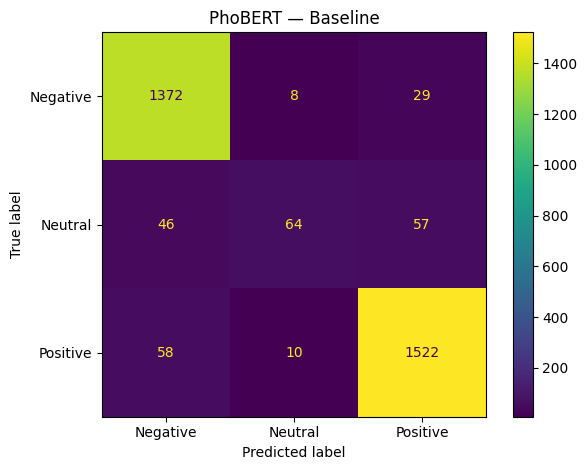

In [ ]:

(
    phobert_baseline,
    history_phobert_baseline
) = train_phobert(
    experiment="Baseline",
    use_class_weight=False
)


In [ ]:
import matplotlib.pyplot as plt

def plot_phobert_history(
    history,
    title,
    file_name
):
    epochs = range(
        1,
        len(history["train_loss"]) + 1
    )

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(12, 4)
    )

    axes[0].plot(
        epochs,
        history["train_loss"],
        marker="o",
        label="Train Loss"
    )
    axes[0].set_title("Training Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_xticks(list(epochs))
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(
        epochs,
        history["val_macro_f1"],
        marker="o",
        label="Validation Macro F1"
    )
    axes[1].set_title("Validation Macro F1")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Macro F1")
    axes[1].set_xticks(list(epochs))
    axes[1].legend()
    axes[1].grid(True)

    fig.suptitle(title)
    plt.tight_layout()

    plt.savefig(
        file_name,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

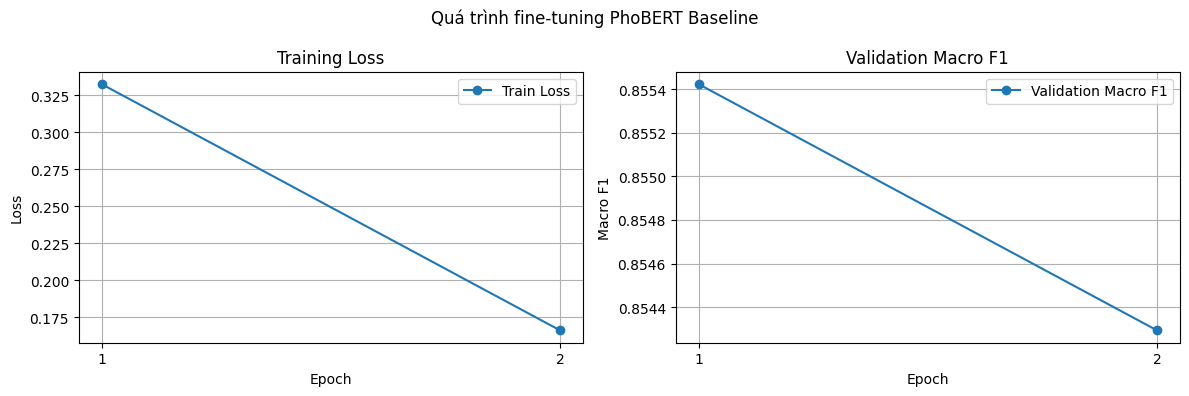

In [ ]:
plot_phobert_history(
    history_phobert_baseline,
    "Quá trình fine-tuning PhoBERT Baseline",
    "anh_trainingPhoBERT_baseline.png"
)

In [ ]:

# Giải phóng bộ nhớ GPU trước thí nghiệm tiếp theo.
del phobert_baseline
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()



## 5. PhoBERT sử dụng Weighted Cross Entropy


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at vinai/phobert-base-v2 and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Weighted Cross-Entropy — Epoch 1/2:   0%|          | 0/715 [00:00<?, ?it/s]

Đánh giá:   0%|          | 0/99 [00:00<?, ?it/s]

Epoch 1: train_loss=0.5650, val_macro_f1=0.8303


Weighted Cross-Entropy — Epoch 2/2:   0%|          | 0/715 [00:00<?, ?it/s]

Đánh giá:   0%|          | 0/99 [00:00<?, ?it/s]

Epoch 2: train_loss=0.3607, val_macro_f1=0.8592


Đánh giá:   0%|          | 0/198 [00:00<?, ?it/s]


PhoBERT — Weighted Cross-Entropy
              precision    recall  f1-score   support

    Negative     0.9452    0.9666    0.9558      1409
     Neutral     0.7120    0.5329    0.6096       167
    Positive     0.9513    0.9572    0.9542      1590

    accuracy                         0.9390      3166
   macro avg     0.8695    0.8189    0.8399      3166
weighted avg     0.9359    0.9390    0.9367      3166



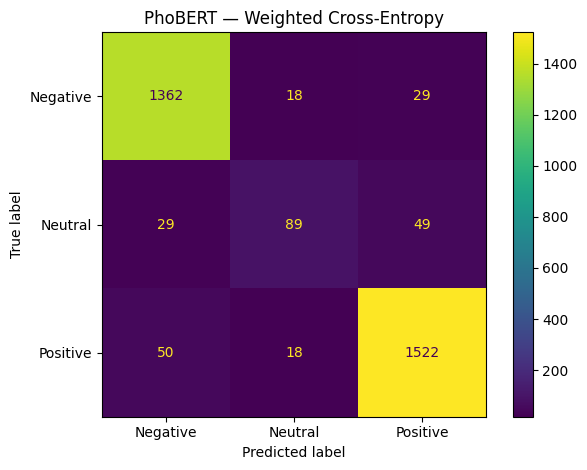

In [ ]:

phobert_balanced, history_phobert_balanced = train_phobert(
    experiment="Weighted Cross-Entropy",
    use_class_weight=True
)

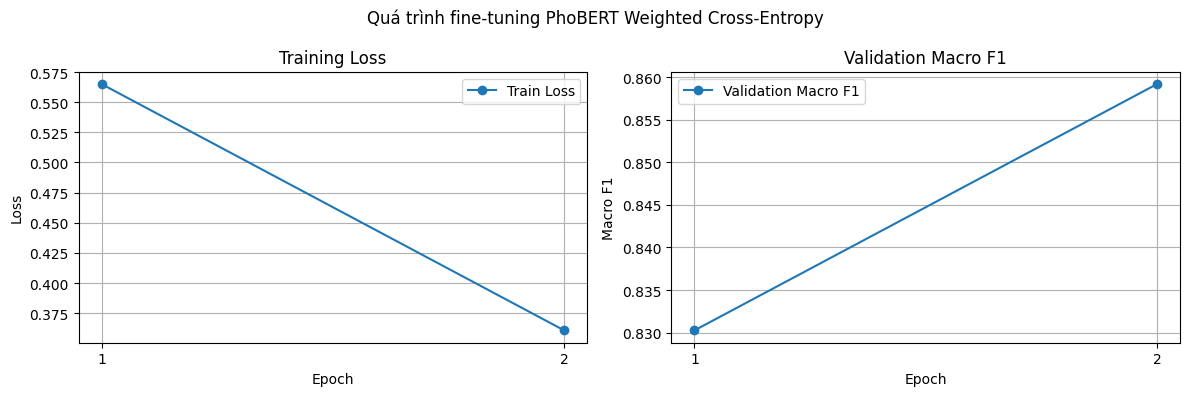

In [ ]:
plot_phobert_history(
    history_phobert_balanced,
    "Quá trình fine-tuning PhoBERT Weighted Cross-Entropy",
    "anh_trainingPhoBERT_weighted.png"
)

In [ ]:

phobert_results = export_results(
    "phobert_results.csv"
)


,Model,Experiment,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Negative Precision,Negative Recall,Negative F1,Neutral Precision,Neutral Recall,Neutral F1,Positive Precision,Positive Recall,Positive F1,Neutral Support
0,PhoBERT,Baseline,0.9343,0.8855,0.7714,0.8057,0.9284,0.9295,0.9737,0.9511,0.7805,0.3832,0.5141,0.9465,0.9572,0.9518,167
1,PhoBERT,Weighted Cross-Entropy,0.9390,0.8695,0.8189,0.8399,0.9367,0.9452,0.9666,0.9558,0.7120,0.5329,0.6096,0.9512,0.9572,0.9542,167


Đã lưu kết quả tại: /content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/phobert_results.csv


In [ ]:
print(
    "Có mô hình Weighted:",
    "phobert_balanced" in globals()
)

print(
    "Có tokenizer:",
    "tokenizer" in globals()
)

if "phobert_balanced" in globals():
    print(
        "Số lớp:",
        phobert_balanced.config.num_labels
    )

Có mô hình Weighted: True
Có tokenizer: True
Số lớp: 3


In [ ]:
phobert_balanced.config.id2label = {
    0: "Negative",
    1: "Neutral",
    2: "Positive",
}

phobert_balanced.config.label2id = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2,
}

phobert_balanced.config.problem_type = (
    "single_label_classification"
)

phobert_balanced.eval()

print(
    "Nhãn mô hình:",
    phobert_balanced.config.id2label
)

Nhãn mô hình: {0: 'Negative', 1: 'Neutral', 2: 'Positive'}


In [ ]:
import os

SAVE_DIR = (
    "/content/drive/MyDrive/"
    "NC_MatCanBang_UIT_VSFC/"
    "SavedModels/"
    "phobert_weighted"
)

os.makedirs(
    SAVE_DIR,
    exist_ok=True
)

phobert_balanced.save_pretrained(
    SAVE_DIR,
    safe_serialization=True
)

tokenizer.save_pretrained(
    SAVE_DIR
)

print("Đã lưu tại:", SAVE_DIR)

print("\nCác tệp đã lưu:")

for file_name in os.listdir(SAVE_DIR):
    print("-", file_name)

Đã lưu tại: /content/drive/MyDrive/NC_MatCanBang_UIT_VSFC/SavedModels/phobert_weighted

Các tệp đã lưu:
- config.json
- model.safetensors
- tokenizer_config.json
- special_tokens_map.json
- added_tokens.json
- vocab.txt
- bpe.codes


In [ ]:
REPO_ID = "hnhut/uit-vsfc-phobert-weighted"

phobert_balanced.push_to_hub(
    REPO_ID,
    safe_serialization=True,
    commit_message=(
        "Upload PhoBERT Weighted "
        "Cross-Entropy model"
    )
)

tokenizer.push_to_hub(
    REPO_ID,
    commit_message=(
        "Upload PhoBERT tokenizer"
    )
)

print(
    "Đã tải mô hình lên Hugging Face:",
    REPO_ID
)

README.md:   0%|          | 0.00/21.0 [00:00<?, ?B/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...f3xv1ob/model.safetensors:   0%|          |  550kB /  540MB            

No files have been modified since last commit. Skipping to prevent empty commit.


Đã tải mô hình lên Hugging Face: hnhut/uit-vsfc-phobert-weighted


In [ ]:
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

HUB_MODEL_ID = (
    "hnhut/uit-vsfc-phobert-weighted"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

hub_tokenizer = AutoTokenizer.from_pretrained(
    HUB_MODEL_ID,
    use_fast=False
)

hub_model = (
    AutoModelForSequenceClassification
    .from_pretrained(
        HUB_MODEL_ID
    )
    .to(DEVICE)
)

hub_model.eval()

print(
    "Tokenizer:",
    type(hub_tokenizer).__name__
)

print(
    "Mô hình:",
    type(hub_model).__name__
)

print(
    "Số lớp:",
    hub_model.config.num_labels
)

print(
    "Tên nhãn:",
    hub_model.config.id2label
)

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

bpe.codes: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/22.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/943 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/540M [00:00<?, ?B/s]

Tokenizer: PhobertTokenizer
Mô hình: RobertaForSequenceClassification
Số lớp: 3
Tên nhãn: {0: 'Negative', 1: 'Neutral', 2: 'Positive'}


In [ ]:
from underthesea import word_tokenize


def predict_from_hub(text):
    segmented_text = word_tokenize(
        str(text),
        format="text"
    )

    inputs = hub_tokenizer(
        segmented_text,
        truncation=True,
        padding=True,
        max_length=128,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(DEVICE)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = hub_model(**inputs)

        probabilities = torch.softmax(
            outputs.logits,
            dim=-1
        )[0]

    predicted_id = int(
        probabilities.argmax().item()
    )

    scores = {
        hub_model.config.id2label[index]:
            round(
                probabilities[index].item(),
                4
            )
        for index in range(3)
    }

    return {
        "Văn bản gốc": text,
        "Văn bản sau tách từ":
            segmented_text,
        "Nhãn dự đoán":
            hub_model.config.id2label[
                predicted_id
            ],
        "Xác suất": scores
    }


result = predict_from_hub(
    "Giảng viên giảng bài dễ hiểu và nhiệt tình."
)

print(result)

{'Văn bản gốc': 'Giảng viên giảng bài dễ hiểu và nhiệt tình.', 'Văn bản sau tách từ': 'Giảng_viên giảng_bài dễ hiểu và nhiệt_tình .', 'Nhãn dự đoán': 'Positive', 'Xác suất': {'Negative': 0.004, 'Neutral': 0.0036, 'Positive': 0.9924}}


In [ ]:
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)
from underthesea import word_tokenize

MODEL_ID = "hnhut/uit-vsfc-phobert-weighted"

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

test_tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    use_fast=False
)

test_model = (
    AutoModelForSequenceClassification
    .from_pretrained(MODEL_ID)
    .to(device)
)

test_model.eval()

text = (
    "Giảng viên giảng bài dễ hiểu "
    "và nhiệt tình."
)

segmented_text = word_tokenize(
    text,
    format="text"
)

inputs = test_tokenizer(
    segmented_text,
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

with torch.no_grad():
    logits = test_model(**inputs).logits

probabilities = torch.softmax(
    logits,
    dim=-1
)[0]

predicted_id = int(
    probabilities.argmax().item()
)

print("Văn bản sau tách từ:", segmented_text)
print(
    "Nhãn dự đoán:",
    test_model.config.id2label[predicted_id]
)
print(
    "Xác suất:",
    probabilities.cpu().numpy()
)

Văn bản sau tách từ: Giảng_viên giảng_bài dễ hiểu và nhiệt_tình .
Nhãn dự đoán: Positive
Xác suất: [0.00403461 0.0035571  0.9924083 ]
